#Entraînement et Benchmark des Modèles de Machine Learning

## Contexte et Objectifs
Dans ce notebook, nous mettons en concurrence plusieurs algorithmes de classification supervisée afin de déterminer le modèle le plus performant pour prédire le niveau de risque de santé mentale des étudiants.

### Démarche :
1. **Instanciation d'un panel d'algorithmes** : Régression Logistique, Arbre de Décision, Random Forest, et Gradient Boosting.
2. **Benchmark comparatif par Validation Croisée (Stratified 5-Fold)** : Évaluation robuste sur plusieurs métriques (Accuracy, Précision Macro, Rappel Macro, F1-Score Macro, F1-Score Pondéré).
3. **Sélection et Entraînement du Meilleur Modèle**.
4. **Évaluation sur l'ensemble de Test indépendant** : Analyse fine via la matrice de confusion.


## 1. Importation des Modules et Chargement des Données
Import des dépendances scikit-learn et des fonctions d'entraînement contenues dans `src.train`.


In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
# Importer les fonctions
from src.train import (
    get_models,
  benchmakig_model,train_model,
       affich_matrix
        
       
   
)


data_path = PROJECT_ROOT / "data" / "raw" / "student_mental_health.csv"
df=pd.read_csv(data_path)  

## 2. Définition des Modèles et Benchmark Comparatif
Exécution de la validation croisée stratifiée 5-folds (`benchmakig_model`) sur les 4 algorithmes.
Les modèles sont encapsulés dans un pipeline scikit-learn intégrant le préprocesseur afin d'éviter tout biais.


In [2]:
get_models()
benchmakig_model(df)

,Model,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
0,Logistic Regression,0.757500,0.756872,0.756928,0.756413,0.756983
1,Gradient Boosting,0.703125,0.701399,0.702343,0.701146,0.701836
2,Random Forest,0.687500,0.681673,0.686547,0.681810,0.682574
3,Decision Tree,0.553750,0.557694,0.553095,0.554054,0.554730


## 3. Entraînement et Évaluation du Meilleur Modèle
La fonction `train_model` sélectionne automatiquement le meilleur modèle issu du benchmark, l'ajuste sur l'ensemble d'entraînement complet (`X_train`, `y_train`) et génère les prédictions sur le jeu de test (`X_test`).
Nous visualisons la matrice de confusion via `affich_matrix`.


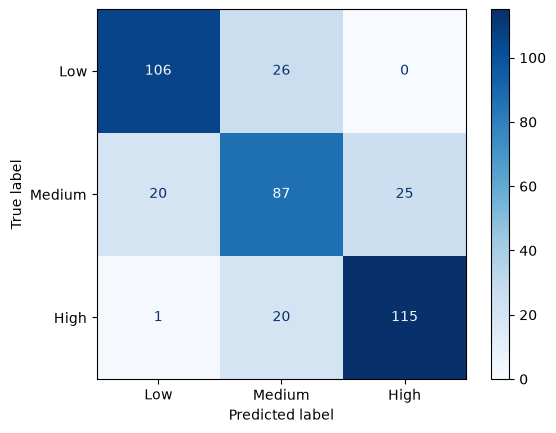

In [4]:
y_test,y_train,X_train,X_test,pipline,y_pred=train_model(df)
affich_matrix(y_test,y_pred)

## 4. Conclusion & Synthèse de l'Entraînement

### Résultats Clés :
1. **Modèle vainqueur** : La **Régression Logistique** se distingue comme le modèle le plus performant et régulier avec environ **75.8% d'accuracy** en validation croisée, surpassant le Gradient Boosting (~70.3%) et la Forêt Aléatoire (~68.8%).
2. **Analyse des erreurs** : La matrice de confusion montre une excellente discrimination sur les classes extrêmes (`Low` et `High`). Les quelques confusions se situent principalement entre `Medium` et les classes adjacentes, ce qui est cohérent avec la nature progressive du risque psychologique.
3. **Prochaine étape** : Procéder à l'optimisation fine des hyperparamètres (GridSearchCV) sur le modèle sélectionné pour maximiser la capacité de généralisation.
